In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [4]:
data = pd.read_csv("../other/mental_health_social_media_dataset.csv")
df = pd.DataFrame(data)
df.head()

,person_name,age,date,gender,platform,daily_screen_time_min,social_media_time_min,negative_interactions_count,positive_interactions_count,sleep_hours,physical_activity_min,anxiety_level,stress_level,mood_level,mental_state
0,Reyansh Ghosh,35,1/1/2024,Male,Instagram,320,160,1,2,7.4,28,2,7,6,Stressed
1,Neha Patel,24,1/12/2024,Female,Instagram,453,226,1,3,6.7,15,3,8,5,Stressed
2,Ananya Naidu,26,1/6/2024,Male,Snapchat,357,196,1,2,7.2,24,3,7,6,Stressed
3,Neha Das,66,1/17/2024,Female,Snapchat,190,105,0,1,8.0,41,2,6,6,Stressed
4,Reyansh Banerjee,31,1/28/2024,Male,Snapchat,383,211,1,2,7.1,22,3,7,6,Stressed


In [5]:
df = df.drop(['person_name', 'date'], axis=1)
df.tail()

,age,gender,platform,daily_screen_time_min,social_media_time_min,negative_interactions_count,positive_interactions_count,sleep_hours,physical_activity_min,anxiety_level,stress_level,mood_level,mental_state
4995,42,Female,WhatsApp,254,64,0,1,7.7,35,1,5,7,At_Risk
4996,33,Female,TikTok,330,214,1,2,7.4,27,3,7,6,Stressed
4997,13,Male,TikTok,403,262,2,2,7.0,20,4,9,4,Stressed
4998,21,Male,TikTok,476,309,2,3,6.6,12,4,9,4,Stressed
4999,42,Female,TikTok,249,162,1,1,7.8,35,2,6,6,Stressed


In [6]:
df.describe()

,age,daily_screen_time_min,social_media_time_min,negative_interactions_count,positive_interactions_count,sleep_hours,physical_activity_min,anxiety_level,stress_level,mood_level
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,29.947800,373.058200,175.331600,0.864200,1.835400,7.134660,22.693400,2.510400,7.107600,5.625800
std,12.279936,106.003916,71.209329,0.555176,0.943443,0.533184,10.602862,0.794996,1.062378,0.759928
min,13.000000,140.000000,35.000000,0.000000,0.000000,6.400000,8.000000,1.000000,5.000000,4.000000
25%,21.000000,310.000000,118.000000,1.000000,1.000000,6.700000,14.000000,2.000000,6.000000,5.000000
50%,27.000000,388.000000,170.000000,1.000000,2.000000,7.100000,21.000000,3.000000,7.000000,6.000000
75%,35.250000,461.000000,231.000000,1.000000,2.000000,7.450000,29.000000,3.000000,8.000000,6.000000
max,69.000000,520.000000,338.000000,2.000000,4.000000,8.300000,46.000000,4.000000,9.000000,7.000000


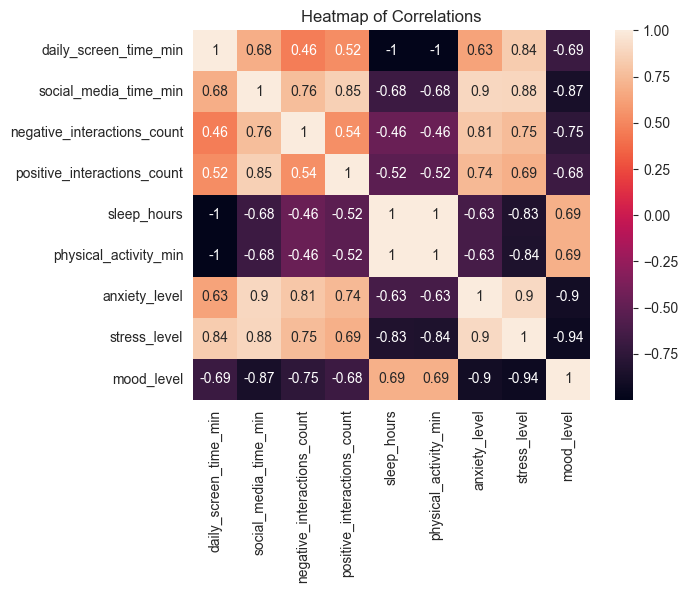

In [8]:
data_corr = df.drop(['age'], axis=1)
correlation_matrix = data_corr.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True)

plt.title('Heatmap of Correlations')
plt.show()

In [17]:
print("\n-----CORRELATION (top pairs)-----")

corr_unstack = correlation_matrix.unstack().reset_index()
corr_unstack.columns = ['var1', 'var2', 'value']
corr_unstack = corr_unstack[corr_unstack['var1'] != corr_unstack['var2']]
corr_unstack['abs_value'] = corr_unstack['value'].abs()
corr_unstack = corr_unstack.sort_values('abs_value', ascending=False).drop_duplicates(subset=['value'])
display(corr_unstack.head(20))


-----CORRELATION (top pairs)-----


,var1,var2,value,abs_value
5,daily_screen_time_min,physical_activity_min,-0.999627,0.999627
36,sleep_hours,daily_screen_time_min,-0.998553,0.998553
41,sleep_hours,physical_activity_min,0.998057,0.998057
79,mood_level,stress_level,-0.935536,0.935536
78,mood_level,anxiety_level,-0.903629,0.903629
61,anxiety_level,stress_level,0.899888,0.899888
15,social_media_time_min,anxiety_level,0.896964,0.896964
64,stress_level,social_media_time_min,0.882873,0.882873
17,social_media_time_min,mood_level,-0.867213,0.867213
12,social_media_time_min,positive_interactions_count,0.854728,0.854728


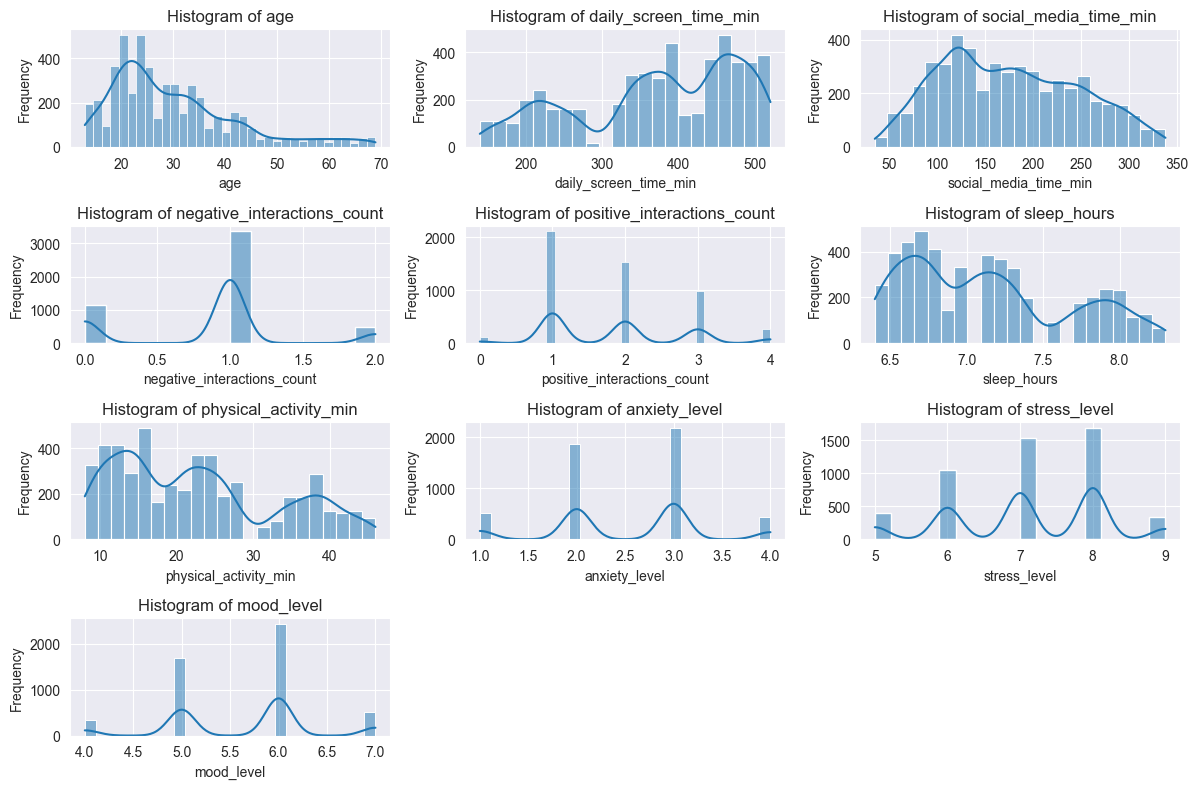

In [16]:
numeric_df = df.drop(['gender','platform','mental_state'],axis=1)
plt.figure(figsize= (12,8))

for i, feature in enumerate(numeric_df.columns):
    plt.subplot(4,3,i+1)
    sns.histplot(numeric_df[feature], kde= True)
    plt.title(f'Histogram of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()